In [39]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import welch
from scipy.io import loadmat

from musim.neuron_models.HH import NegroFarina
from musim.core.stimuli import trapezoid_drive
from musim.emg.emg_routines import convolutive_mixture, generate_emg_noise


In [40]:
"""
Helper function for calculating the PSD of the signal 

"""

def calc_PSD(sig, fsamp=2048, nperseg=2048, noverlap=2048/2):
    '''
    Compute the power spectral density for each channel using Welch's method.

    Parameters
    ----------
    sig : ndarray
        Multi-channel signal of shape ``(Channels, Samples)``
    fsamp : float
        Sampling rate in Hz
    nperseg : int
        Number of data points per segment
    overlap : int
        Number of overlapping samples

    Returns
    -------
    P : np.ndarray
        PSD estimate of shape ``(n_channels, n_freqs)```
    f : np.ndarray
        Vector of frequencies of shape ``(n_freqs, )``
    '''

    f, _ = welch(sig[0,:], fs=fsamp, nperseg=nperseg, noverlap=noverlap)

    P = np.zeros((sig.shape[0], f.shape[0]))

    for i in range(sig.shape[0]):
        _ , P[i,:] = welch(sig[i,:], fs=fsamp, nperseg=nperseg, noverlap=noverlap)

    return P, f

In [ ]:
""" 
Load Experimental MUAPs curated by Robin Rohlen, see

.. [1] Klotz and Rohlen, "Revisiting convolutive blind source separation 
       for identifying spiking motor neuron activity: from theory to 
       practice", Journal of Neural Engineering, 2025 

"""


mat = loadmat("../data/muaps_RT_S1.mat", struct_as_record=False, squeeze_me=True)

n_mu = mat["muap"].shape[0]
muaps = np.zeros((n_mu, 256, 101))

for mu_idx in range(n_mu):
    # Devide by 150 to obtain physical units (mV)
    muaps[mu_idx, :, :] = mat["muap"][mu_idx] / 150

RT = mat["RT"]

In [ ]:
""" 
Simulate motor neuron spikes
using a pool of 100 neurons

"""

n_mn = 100
dt = 0.025

CI = trapezoid_drive(
    t_plateau=10000, # milli seconds
    t_ramp=3000,     # milli seconds
    dt=dt,          # milli seconds
    max_CI=10,       # nano ampere
    min_CI=3,        # nano ampere   
    n_mu=100,
)

model = NegroFarina(
    n_mn=n_mn,
    dist_exp=3,
)

v, spikes = model.simulate(CI, dt=dt)

Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recordings` for details.
Added 1 recordings. See `.recor

In [ ]:
"""
Randomly select 100 MUAPs and colvolve them 
by the computed spike times. Furthermore, we
genrarte additive noise.

"""

rng = np.random.default_rng(12)

muap_idx = np.sort(rng.choice(np.arange(n_mu), size=100, replace=False))

emg = convolutive_mixture(
    muaps=muaps[muap_idx, :, :],
    spikes=spikes,
    t_dur=17,
    fsamp=2048
)

noise = generate_emg_noise(
    n_channels=emg.shape[0],
    n_samples=emg.shape[1],
    fs=2048,
    med_psd=80.83e-8, # mV^2/Hz
    alpha=0.2,
    line_snr_db=10,
    independent_line_phase=False
)

data = emg + noise

print(f"The SNR is {10 * np.log10(np.mean(emg**2) / np.mean(noise**2))} dB")

The SNR is 33.63324997992355 dB


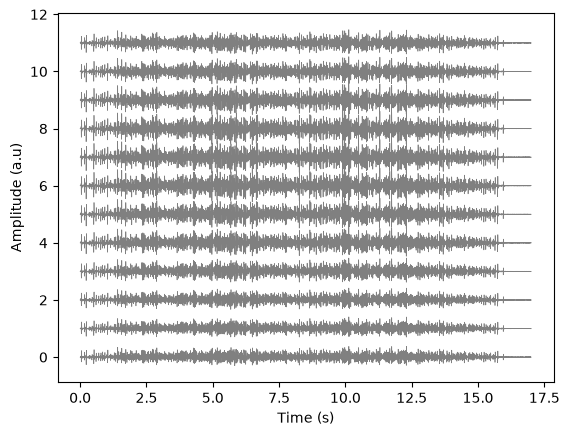

In [46]:
"""
Plot time series data on a few channels
"""

t = np.linspace(0, 17, data.shape[1])

plt.figure()
for i in range(12):
    plt.plot(t, data[i, :] / 10 + i, color="gray", lw=0.5)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (a.u)")
plt.show()

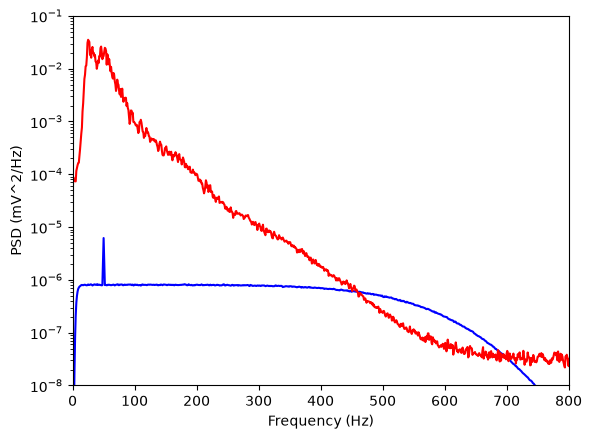

In [48]:
""" 
Calculate the PSD of the signal and the noise

"""

Pn, fn = calc_PSD(noise)
Ps, fs = calc_PSD(emg)

plt.figure()
plt.semilogy(fn, np.mean(Pn, axis=0), color="blue", label="Noise Power")
plt.semilogy(fs, np.mean(Ps, axis=0), color="red", label="Signal Power")
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (mV^2/Hz)")
plt.xlim(0, 800)
plt.ylim(1e-8, 1e-1)
plt.show()